# Non-graph baselines for traffic forecasting

**DSAIT4305 group project**

Three baselines that forecast traffic without using the road graph: persistence, seasonal, and linear regression. Each is in its own section, and the notebook prints what it learns and what it scores so the training and testing steps are visible.

**Objectives**

* Forecast traffic intensity 15, 30, 45 and 60 minutes ahead at each sensor, without the graph.
* Report MAE and RMSE in vehicles/hour on genuinely observed targets.


## Data

Preprocessed arrays from the shared pipeline: 6 connected central districts, about 1,054 sensors, 2024, 15-minute steps.

* `features.npz`: intensity and its observation mask on a `[time, sensor]` grid, standardised per sensor.
* `params.npz`: the per-sensor mean and standard deviation, used to convert back to vehicles/hour.
* `windows.csv`: each forecast window, with its origin step, the four targets (h1..h4), and the train/val/test split.


In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data_dir = "data/forecast_dataset"

features = np.load(f"{data_dir}/features.npz")
params = np.load(f"{data_dir}/params.npz")
windows = pd.read_csv(f"{data_dir}/windows.csv")

intensity = features["intensity"]        # [T, N] standardised per sensor
mask = features["intensity_mask"]        # [T, N] True where genuinely observed
timestamps = pd.DatetimeIndex(features["timestamps"])
mean = params["scaler_mean"]
std = params["scaler_std"]

print(f"{intensity.shape[1]} sensors, {intensity.shape[0]} time steps")
for s in ["train", "val", "test"]:
    print(f"{s}: {(windows['split'] == s).sum()} windows")

1054 sensors, 35136 time steps
train: 23415 windows
val: 5853 windows
test: 5853 windows


In [3]:
intensity = np.where(mask, intensity, np.nan)   # drop filler values so they are ignored

slot = timestamps.hour.to_numpy() * 4 + timestamps.minute.to_numpy() // 15
time_of_week = timestamps.dayofweek.to_numpy() * 96 + slot   # weekday x 15-min slot, 0..671

horizons = {"h1": 15, "h2": 30, "h3": 45, "h4": 60}
history_steps = np.arange(-5, 1)   # the 6 input steps up to and including the origin

def history_rows(origins):
    # standardised intensity over the 6-step input window: [windows, 6, N], gaps -> 0
    return np.nan_to_num(intensity[origins[:, None] + history_steps[None, :]])

## Model 1: seasonal

Each sensor's average level for a given weekday and time of day, learned from the training period only so nothing leaks from validation or test. The learned table has one row per time-of-week bucket and one column per sensor.


In [4]:
t0 = time.time()
train_end = windows.loc[windows["split"] == "train", "target_timestamp_h4"].max()
train_steps = timestamps <= pd.Timestamp(train_end)

profile = pd.DataFrame(intensity[train_steps]).groupby(time_of_week[train_steps]).mean()
profile = profile.reindex(range(7 * 96)).to_numpy()
profile = np.nan_to_num(profile)   # unseen buckets fall back to the sensor mean (0)
fit_s = {"persistence": 0.0, "seasonal": time.time() - t0}   # training time per model
print(f"seasonal fit: {fit_s['seasonal']:.2f}s")
print("learned profile shape (buckets x sensors):", profile.shape)

def seasonal_predict(target_index):
    return profile[time_of_week[target_index]]

seasonal fit: 0.28s
learned profile shape (buckets x sensors): (672, 1054)


## Model 2: persistence

Predict that the value at each horizon equals the last observed value at the forecast origin. There is nothing to fit. When the origin reading is missing, it falls back to the seasonal level.


In [5]:
def persistence_predict(origin_index, target_index):
    last = intensity[origin_index]
    return np.where(np.isnan(last), seasonal_predict(target_index), last)

## Model 3: linear regression

A least-squares fit of the target on the last six observed steps, one model per horizon, pooled over all sensors. Same closed-form least-squares idea as Lab 1.1, without the graph term. We fit on a bounded sample of windows so the fit stays quick at any network size. The fitted model is seven numbers per horizon: an intercept and one weight per input step.


In [6]:
t0 = time.time()
train = windows[windows["split"] == "train"]
n_sensors = intensity.shape[1]
step = max(1, len(train) // max(1, 400_000 // n_sensors))
sample = train.iloc[::step]

hist = history_rows(sample["origin_index"].to_numpy())
X = np.column_stack([np.ones(hist.shape[0] * n_sensors),
                     hist.transpose(0, 2, 1).reshape(-1, 6)])

coefs = {}
for h in horizons:
    y = intensity[sample[f"target_index_{h}"].to_numpy()].ravel()
    seen = ~np.isnan(y)
    coefs[h], *_ = np.linalg.lstsq(X[seen], y[seen], rcond=None)
fit_s["linear"] = time.time() - t0
print(f"linear fit: {fit_s['linear']:.2f}s on {len(sample)} windows")
print("h1 coefficients [intercept, w-5..w0]:", np.round(coefs["h1"], 3))

def linear_predict(origin_index, h):
    history = history_rows(origin_index)
    return coefs[h][0] + np.tensordot(history, coefs[h][1:], axes=([1], [0]))

linear fit: 0.30s on 384 windows
h1 coefficients [intercept, w-5..w0]: [-0.006 -0.045 -0.022  0.041  0.115  0.256  0.597]


## Evaluation

For each split and horizon we predict with all three models, convert back to vehicles/hour with `x = z * std + mean`, and score MAE and RMSE on the observed targets only. The scored counts below show how many real target values each split is measured on.


In [7]:
rows = []
scored = {}
infer_s = {}
for split in ["val", "test"]:
    w = windows[windows["split"] == split]
    origin = w["origin_index"].to_numpy()
    for h, minutes in horizons.items():
        target = w[f"target_index_{h}"].to_numpy()
        truth = intensity[target]
        predictors = {
            "persistence": lambda: persistence_predict(origin, target),
            "seasonal": lambda: seasonal_predict(target),
            "linear": lambda: linear_predict(origin, h),
        }
        preds = {}
        for name, predict in predictors.items():
            t0 = time.perf_counter()
            preds[name] = predict()
            if split == "test":   # time to predict every test window and sensor, summed over horizons
                infer_s[name] = infer_s.get(name, 0.0) + time.perf_counter() - t0

        seen = ~np.isnan(truth)
        scored[split] = scored.get(split, 0) + int(seen.sum())
        truth_vph = (truth * std + mean)[seen]
        for name, pred in preds.items():
            error = (pred * std + mean)[seen] - truth_vph
            rows.append({"split": split, "model": name, "horizon_min": minutes,
                         "MAE": np.abs(error).mean(), "RMSE": np.sqrt((error ** 2).mean())})

print("scored target values:", scored)
results = pd.DataFrame(rows)
results.round(1)

scored target values: {'val': 23270389, 'test': 23200373}


,split,model,horizon_min,MAE,RMSE
0,val,persistence,15,60.7,119.2
1,val,seasonal,15,98.8,263.1
2,val,linear,15,64.3,128.9
3,val,persistence,30,77.5,158.0
4,val,seasonal,30,98.8,263.1
5,val,linear,30,82.6,165.5
6,val,persistence,45,94.0,194.0
7,val,seasonal,45,98.8,263.1
8,val,linear,45,100.0,197.8
9,val,persistence,60,110.0,227.5


## One worked example

A single test sensor at a single time so you can see the inputs, each model's prediction and the actual value side by side.

The window printed below is a hard one: a late-night reading that fell to about 100 and then jumped back to 232, so all three models under-predict it. A single point like this is noisy. The MAE and RMSE above average over more than 23 million test targets, and those are what actually describe the models, not any one window.

In [8]:
ex = windows[windows["split"] == "test"].iloc[0]
o = int(ex["origin_index"])
t = int(ex["target_index_h1"])# the 15-minute target
s = int(np.where(mask[t])[0][0]) # a sensor with a real reading at that target

def to_vph(z):
    return z * std[s] + mean[s]

recent = np.nan_to_num(intensity[o - 5:o + 1, s])
last = intensity[o, s]
pers = last if not np.isnan(last) else profile[time_of_week[t], s]
lin = coefs["h1"][0] + coefs["h1"][1:] @ recent

print("sensor", int(features["sensor_ids"][s]), "| origin", ex["origin_timestamp"])
print("last 6 readings (veh/h):", np.round(to_vph(recent), 1))
print(f"persistence predicts : {to_vph(pers):7.1f}")
print(f"seasonal predicts    : {to_vph(profile[time_of_week[t], s]):7.1f}")
print(f"linear predicts      : {to_vph(lin):7.1f}")
print(f"actual value         : {to_vph(intensity[t, s]):7.1f}")

sensor 3395 | origin 2024-10-31 23:45:00
last 6 readings (veh/h): [219. 292. 280. 251. 104. 123.]
persistence predicts :   123.0
seasonal predicts    :   165.9
linear predicts      :   138.9
actual value         :   232.0


## Results

MAE and RMSE against the forecast horizon, on the test split.


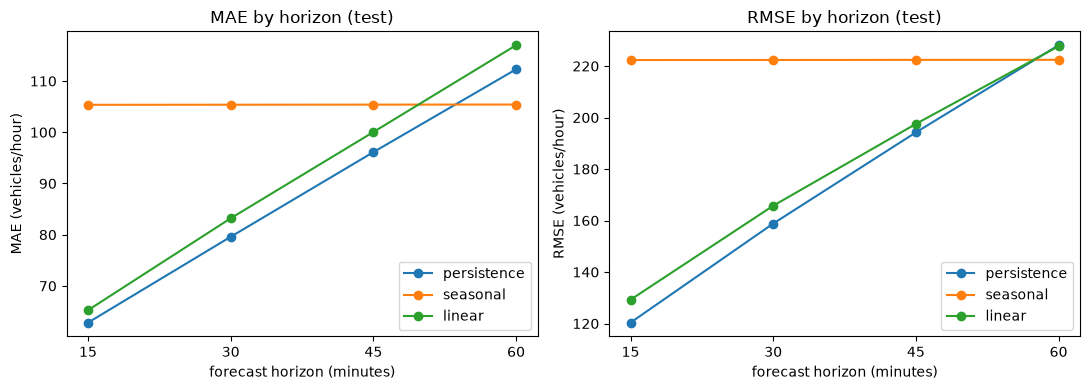

In [9]:
test = results[results["split"] == "test"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for metric, ax in zip(["MAE", "RMSE"], axes):
    for model in ["persistence", "seasonal", "linear"]:
        sub = test[test["model"] == model].sort_values("horizon_min")
        ax.plot(sub["horizon_min"], sub[metric], marker="o", label=model)
    ax.set_xlabel("forecast horizon (minutes)")
    ax.set_ylabel(f"{metric} (vehicles/hour)")
    ax.set_title(f"{metric} by horizon (test)")
    ax.set_xticks([15, 30, 45, 60])
    ax.legend()
plt.tight_layout()
plt.show()

In [10]:
# parameters: persistence is a rule (its fallback reuses the seasonal profile), the seasonal
# model stores one value per weekly slot and sensor, the linear model 7 coefficients per horizon
n_params = {"persistence": 0, "seasonal": int(profile.size), "linear": int(sum(c.size for c in coefs.values()))}
results["seed"] = 0                       # deterministic, so one "seed"
results["n_params"] = results["model"].map(n_params)
results["epochs"] = 0                     # closed-form fits, no epochs
results["train_s"] = results["model"].map(fit_s)
results["epoch_s"] = float("nan")
results["infer_s"] = results["model"].map(infer_s)
results["peak_gb"] = float("nan")         # CPU only
results.to_csv(f"{data_dir}/reports/baseline_nongraph_results.csv", index=False)

## Observations
On the test set the three models rank the same way at every horizon: persistence is best at 15, 30 and 45 minutes, the seasonal average overtakes it at 60 minutes, and linear regression stays just behind persistence throughout.

Persistence does well because traffic is strongly tied to its recent past. Its average miss is about 63 vehicles/hour at 15 minutes and grows to about 112 at 60 minutes, as the last reading becomes a weaker guide further out. The seasonal average is flat near 105 across every horizon, since a weekly pattern does not depend on how far ahead you look. Its RMSE of about 222 sits far above its MAE of 105, which means it is fine on average but misses the sharp peaks. That flat error finally beats persistence's growing one at 60 minutes.

Linear regression lands almost on top of persistence, and the fitted weights show why: the coefficient on the most recent step is about 0.60 and the six weights sum to roughly 0.94, so the model learned to mostly repeat the last reading, lightly shrunk toward the average. The shrinkage helps its squared error a little and costs its absolute error a little, which is what the table shows.

A single prediction can still be far off, as the worked example shows, but the reported errors average over more than 23 million test targets, so they describe the typical case rather than any one window.

The takeaway for the project: simple non-graph methods all cluster around persistence, so the graph model has a demanding floor. It must beat persistence at the short horizons and the seasonal mean at an hour out before the network structure can be said to help.